In [6]:
import yfinance as yf

# VIX
vix = yf.download("^VIX", start="2010-01-01", end="2023-12-31")
vix.to_csv("../data/vix.csv")
print(vix.head())

[*********************100%***********************]  1 of 1 completed

Price           Close       High        Low       Open Volume
Ticker           ^VIX       ^VIX       ^VIX       ^VIX   ^VIX
Date                                                         
2010-01-04  20.040001  21.680000  20.030001  21.680000      0
2010-01-05  19.350000  20.129999  19.340000  20.049999      0
2010-01-06  19.160000  19.680000  18.770000  19.590000      0
2010-01-07  19.059999  19.709999  18.700001  19.680000      0
2010-01-08  18.129999  19.270000  18.110001  19.270000      0


In [11]:
px = yf.download("^PXE", start="2010-01-01", end="2023-12-31")
px.to_csv("../data/pxe.csv")
print(px.head())

$^PXE: possibly delisted; no timezone found
[*********************100%***********************]  1 of 1 completed

1 Failed download:
['^PXE']: possibly delisted; no timezone found


Empty DataFrame
Columns: [(Adj Close, ^PXE), (Close, ^PXE), (High, ^PXE), (Low, ^PXE), (Open, ^PXE), (Volume, ^PXE)]
Index: []


In [14]:
import pandas as pd
import pandas_datareader.data as web
import datetime

# 1. Диапазон дат
start = datetime.datetime(2010, 1, 1)
end = datetime.datetime(2023, 12, 31)

# 2. LRHUTTTTCZM156S - Код гармонизированного уровня безработицы для Чехии во FRED (Eurostat/OECD)
# Данные скорректированы с учетом сезонности (Seasonally Adjusted)
print("Загрузка данных безработицы Чехии (Eurostat/FRED)...")
unemployment = web.DataReader('LRHUTTTTCZM156S', 'fred', start, end)

# 3. Приведение к читаемому виду
unemployment.index.name = 'Date'
unemployment.rename(columns={'LRHUTTTTCZM156S': 'Unemployment_Rate'}, inplace=True)

# 4. Сохранение в CSV
file_name = "czech_unemployment_2010_2023.csv"
unemployment.to_csv(file_name)
print(f"Данные сохранены в файл: {file_name}")
print(unemployment.head())


Загрузка данных безработицы Чехии (Eurostat/FRED)...
Данные сохранены в файл: czech_unemployment_2010_2023.csv
            Unemployment_Rate
Date                         
2010-01-01                7.8
2010-02-01                7.9
2010-03-01                7.6
2010-04-01                7.4
2010-05-01                7.4


In [16]:
from pathlib import Path

DATA_DIR = Path("../data")

files = {
    "train": DATA_DIR / "train.csv",
    "validazione": DATA_DIR / "validazione.csv",
    "cnb": DATA_DIR / "cnb.csv",
    "eur_czk": DATA_DIR / "eur_czk_2010_2023.csv",
    "unemployment": DATA_DIR / "czech_unemployment_2010_2023.csv",
    "px": DATA_DIR / "px.csv",
    "vix": DATA_DIR / "vix.csv",
}

for name, path in files.items():
    print("=" * 70)
    print(f"📁 {name}: {path}")
    print("=" * 70)
    
    if not path.exists():
        print("❌ Файл не найден")
        continue
    
    try:
        df = pd.read_csv(path, nrows=5)
        full = pd.read_csv(path)
        
        print(f"Shape: {full.shape}")
        print(f"Columns ({len(full.columns)}):")
        print(full.columns.tolist())
        print("\nDtypes:")
        print(full.dtypes.value_counts())
        print("\nПервые 3 строки:")
        print(full.head(3).to_string())
        
        # Для кредитного — баланс классов
        if "TARGET" in full.columns:
            print("\nTARGET distribution:")
            print(full["TARGET"].value_counts())
            print(f"Доля дефолтов: {full['TARGET'].mean():.4f}")
        
        # Пропуски топ-10
        print("\nТоп-10 пропусков:")
        print(full.isnull().sum().sort_values(ascending=False).head(10))
        
    except Exception as e:
        print(f"❌ Ошибка: {e}")
    
    print("\n")

📁 train: ..\data\train.csv
Shape: (215257, 102)
Columns (102):
['ID', 'NAME_CONTRACT_TYPE', 'GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'DAYS_AGE', 'DAYS_EMPLOYMENT', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'ORGANIZATION_TYPE', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'YEARS_BUILD_AVG', 'ELEVATORS_AVG', 'ENTRANCES_AVG', 'FLOORSMAX_AVG', 'FLOORSMIN_AVG', 'LIVINGAREA_AVG', 'NONLIVINGAPARTM

In [20]:
import yfinance as yf
import pandas as pd

# 1. Указываем тикер индекса волатильности VIX
ticker = "^VIX"

# 2. Задаем временной интервал (с запасом в 1 день для yfinance)
start_date = "2010-01-01"
end_date = "2024-01-01"

print("Загрузка исторических данных индекса VIX...")
vix_data = yf.download(ticker, start=start_date, end=end_date)

if not vix_data.empty:
    vix_data.reset_index(inplace=True)
    
    # Оставляем только Дату и цену закрытия (Close)
    final_vix = vix_data[['Date', 'Close']].copy()
    final_vix.columns = ['Date', 'VIX_Index']
    
    # Сохраняем в CSV
    file_name = "vix_2010_2023.csv"
    final_vix.to_csv(file_name, index=False)
    print(f"Успешно сохранено! Файл: {file_name}")
    print(f"Всего строк (торговых дней): {len(final_vix)}")
else:
    print("Ошибка при загрузке данных VIX.")


[*********************100%***********************]  1 of 1 completed

Загрузка исторических данных индекса VIX...
Успешно сохранено! Файл: vix_2010_2023.csv
Всего строк (торговых дней): 3522


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Настройка графиков
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
pd.set_option('display.max_columns', 100)

# Пути
ROOT_DIR = Path("..").resolve() # Если ноутбук в папке notebooks, то поднимаемся на уровень выше
PROCESSED_DIR = ROOT_DIR / "data" / "processed"

print("Библиотеки загружены.")

Библиотеки загружены.


In [2]:
# Загружаем данные
train = pd.read_csv(PROCESSED_DIR / "train_processed.csv")
val = pd.read_csv(PROCESSED_DIR / "val_processed.csv")
test = pd.read_csv(PROCESSED_DIR / "test_processed.csv")

print(f"Размер Train: {train.shape}")
print(f"Размер Val:   {val.shape}")
print(f"Размер Test:  {test.shape}")

# Смотрим на типы данных
print("\nТипы данных в Train:")
print(train.dtypes.value_counts())

Размер Train: (215257, 145)
Размер Val:   (46126, 145)
Размер Test:  (46128, 145)

Типы данных в Train:
float64    87
int64      41
object     17
Name: count, dtype: int64


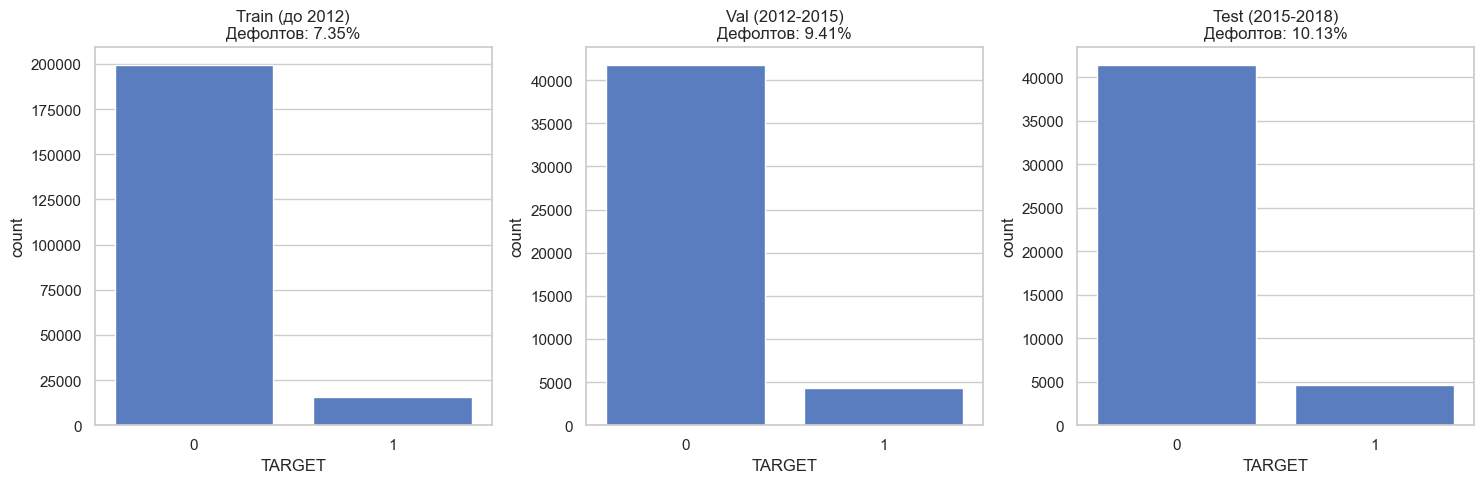

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Train
sns.countplot(x='TARGET', data=train, ax=axes[0])
axes[0].set_title(f'Train (до 2012)\nДефолтов: {train["TARGET"].mean()*100:.2f}%')

# Val
sns.countplot(x='TARGET', data=val, ax=axes[1])
axes[1].set_title(f'Val (2012-2015)\nДефолтов: {val["TARGET"].mean()*100:.2f}%')

# Test
sns.countplot(x='TARGET', data=test, ax=axes[2])
axes[2].set_title(f'Test (2015-2018)\nДефолтов: {test["TARGET"].mean()*100:.2f}%')

plt.tight_layout()
plt.show()

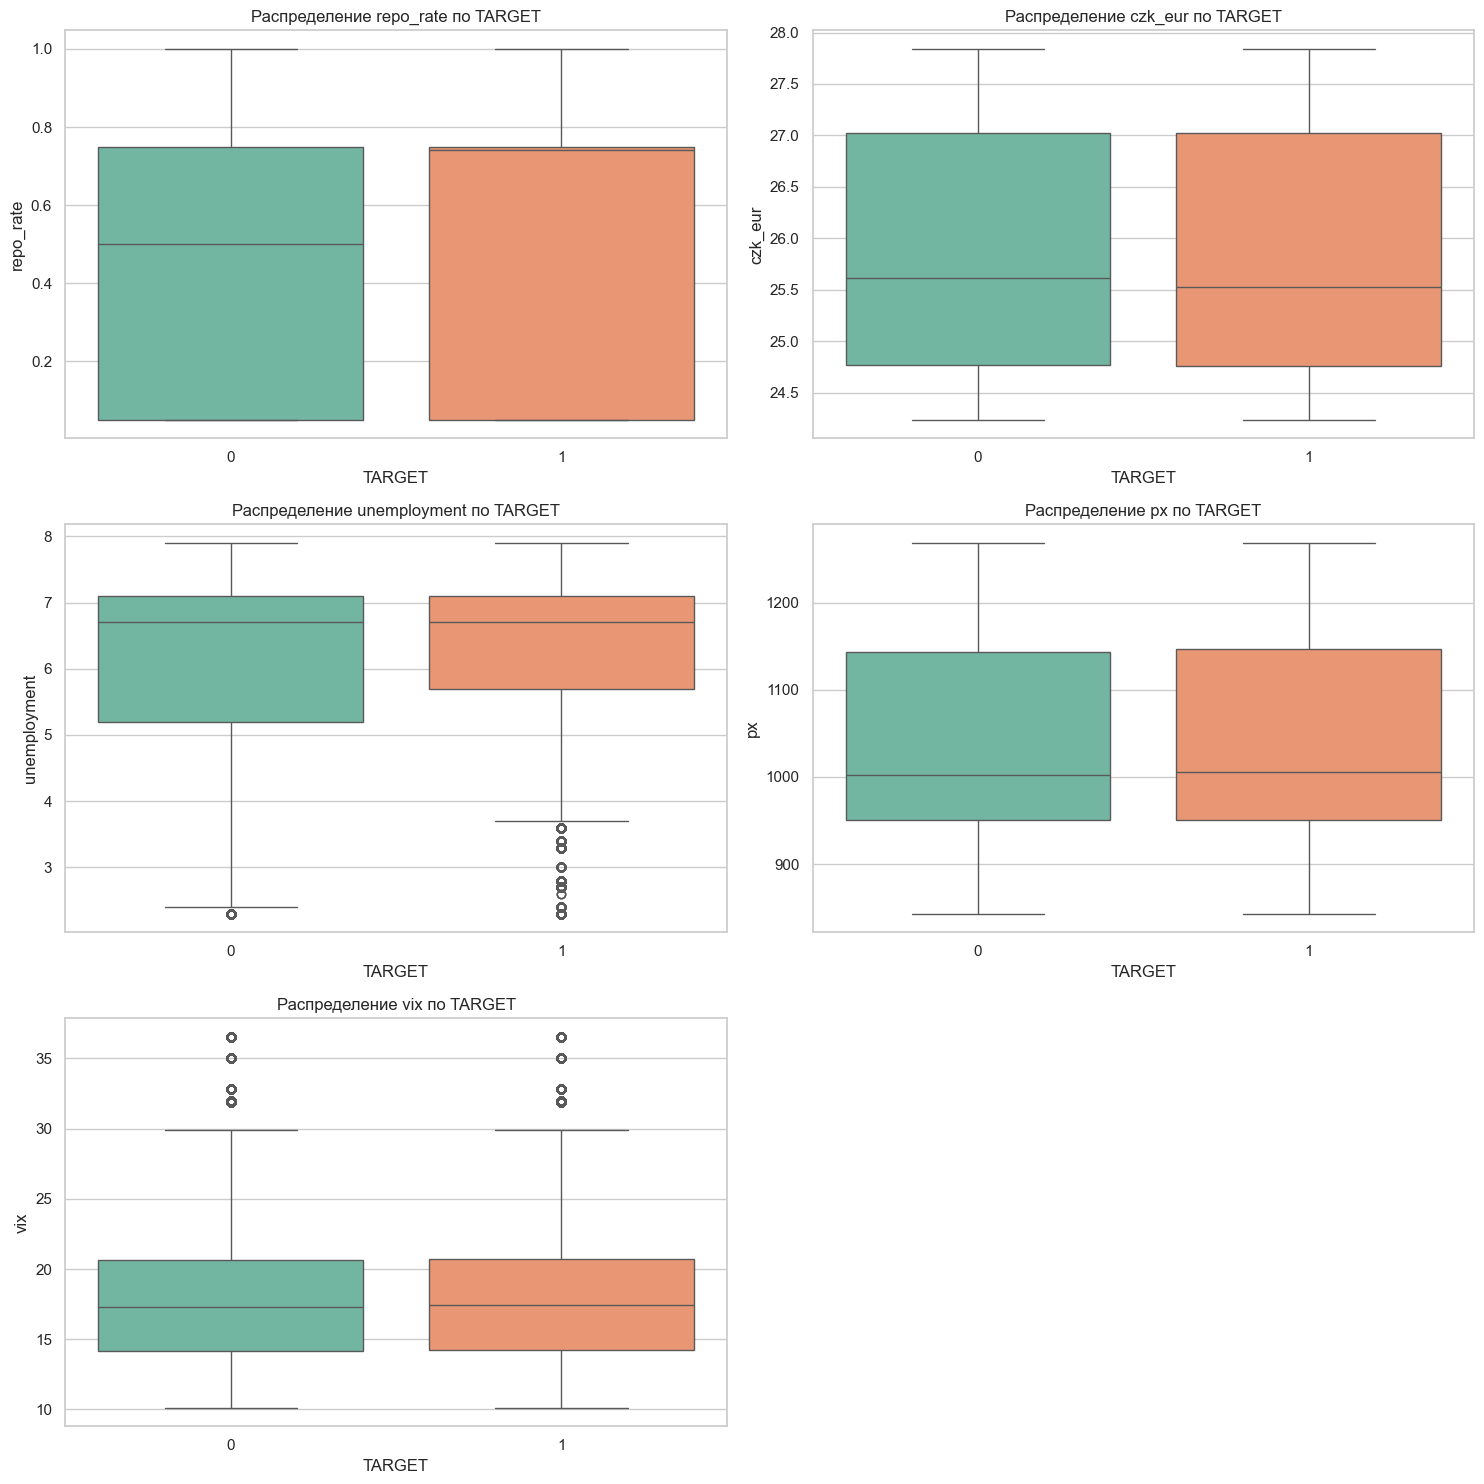

In [4]:
macro_cols = ['repo_rate', 'czk_eur', 'unemployment', 'px', 'vix']

fig, axes = plt.subplots(3, 2, figsize=(15, 15))
axes = axes.flatten()

for i, col in enumerate(macro_cols):
    # Boxplot показывает медиану и разброс
    sns.boxplot(x='TARGET', y=col, data=train, ax=axes[i], palette="Set2")
    axes[i].set_title(f'Распределение {col} по TARGET')

# Удаляем пустой 6-й график
fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

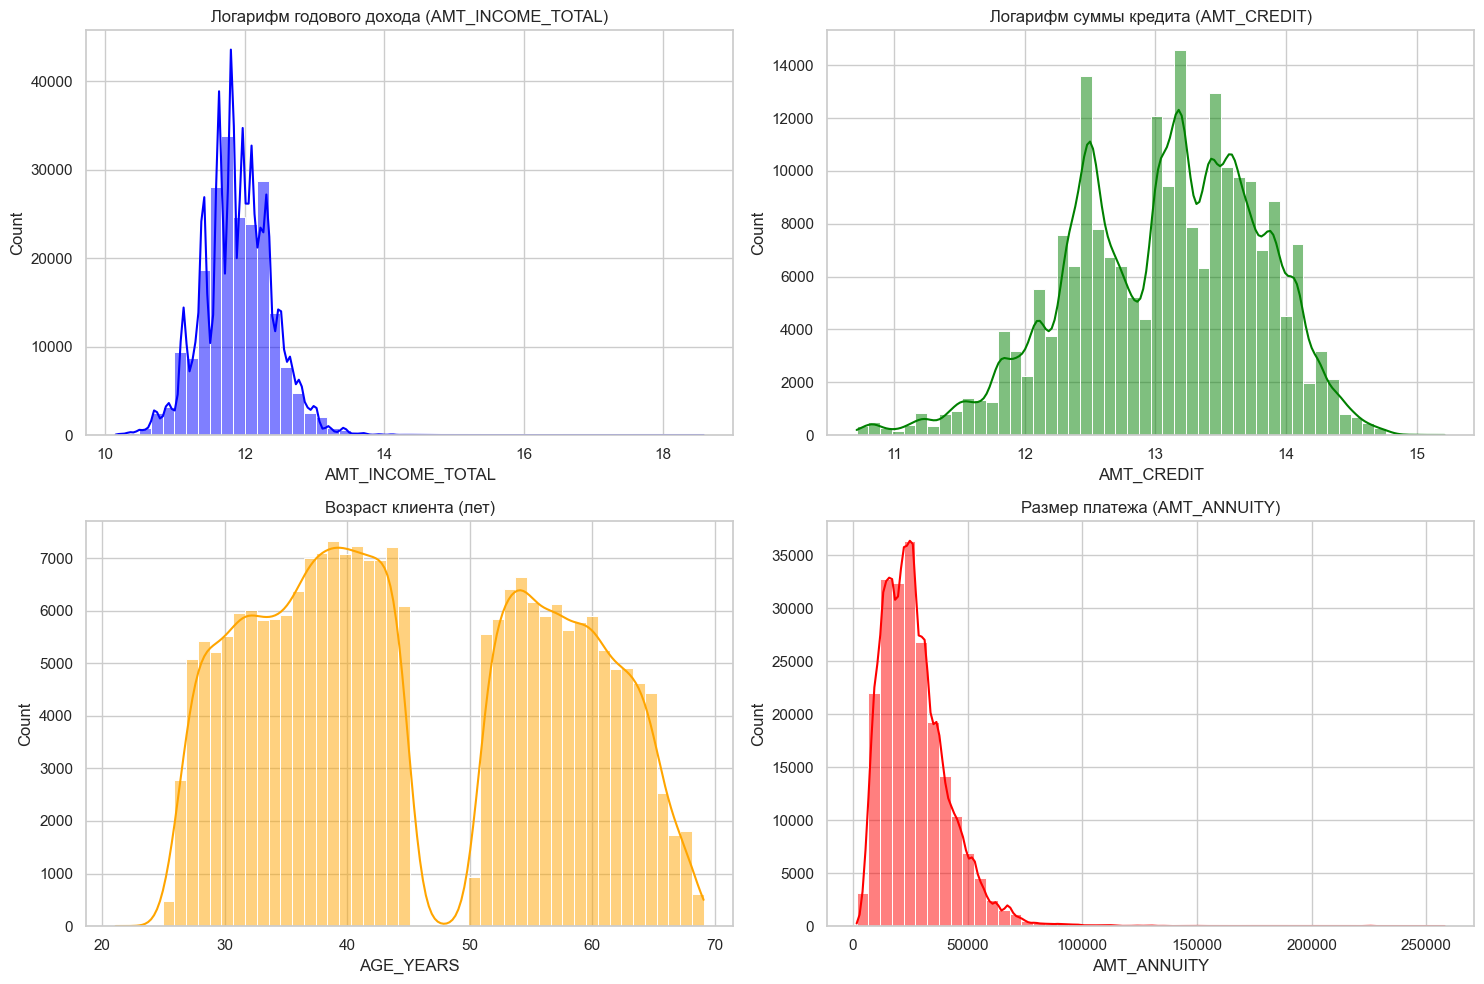

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Доход (логарифмируем, так как есть выбросы в миллионы)
sns.histplot(np.log1p(train['AMT_INCOME_TOTAL']), bins=50, kde=True, ax=axes[0, 0], color='blue')
axes[0, 0].set_title('Логарифм годового дохода (AMT_INCOME_TOTAL)')

# Сумма кредита
sns.histplot(np.log1p(train['AMT_CREDIT']), bins=50, kde=True, ax=axes[0, 1], color='green')
axes[0, 1].set_title('Логарифм суммы кредита (AMT_CREDIT)')

# Возраст (переводим дни в годы: DAYS_BIRTH отрицательный, берем модуль)
train['AGE_YEARS'] = train['DAYS_BIRTH'].abs() / 365.25
sns.histplot(train['AGE_YEARS'], bins=50, kde=True, ax=axes[1, 0], color='orange')
axes[1, 0].set_title('Возраст клиента (лет)')

# Аннуитет (ежегодный платеж)
sns.histplot(train['AMT_ANNUITY'], bins=50, kde=True, ax=axes[1, 1], color='red')
axes[1, 1].set_title('Размер платежа (AMT_ANNUITY)')

plt.tight_layout()
plt.show()

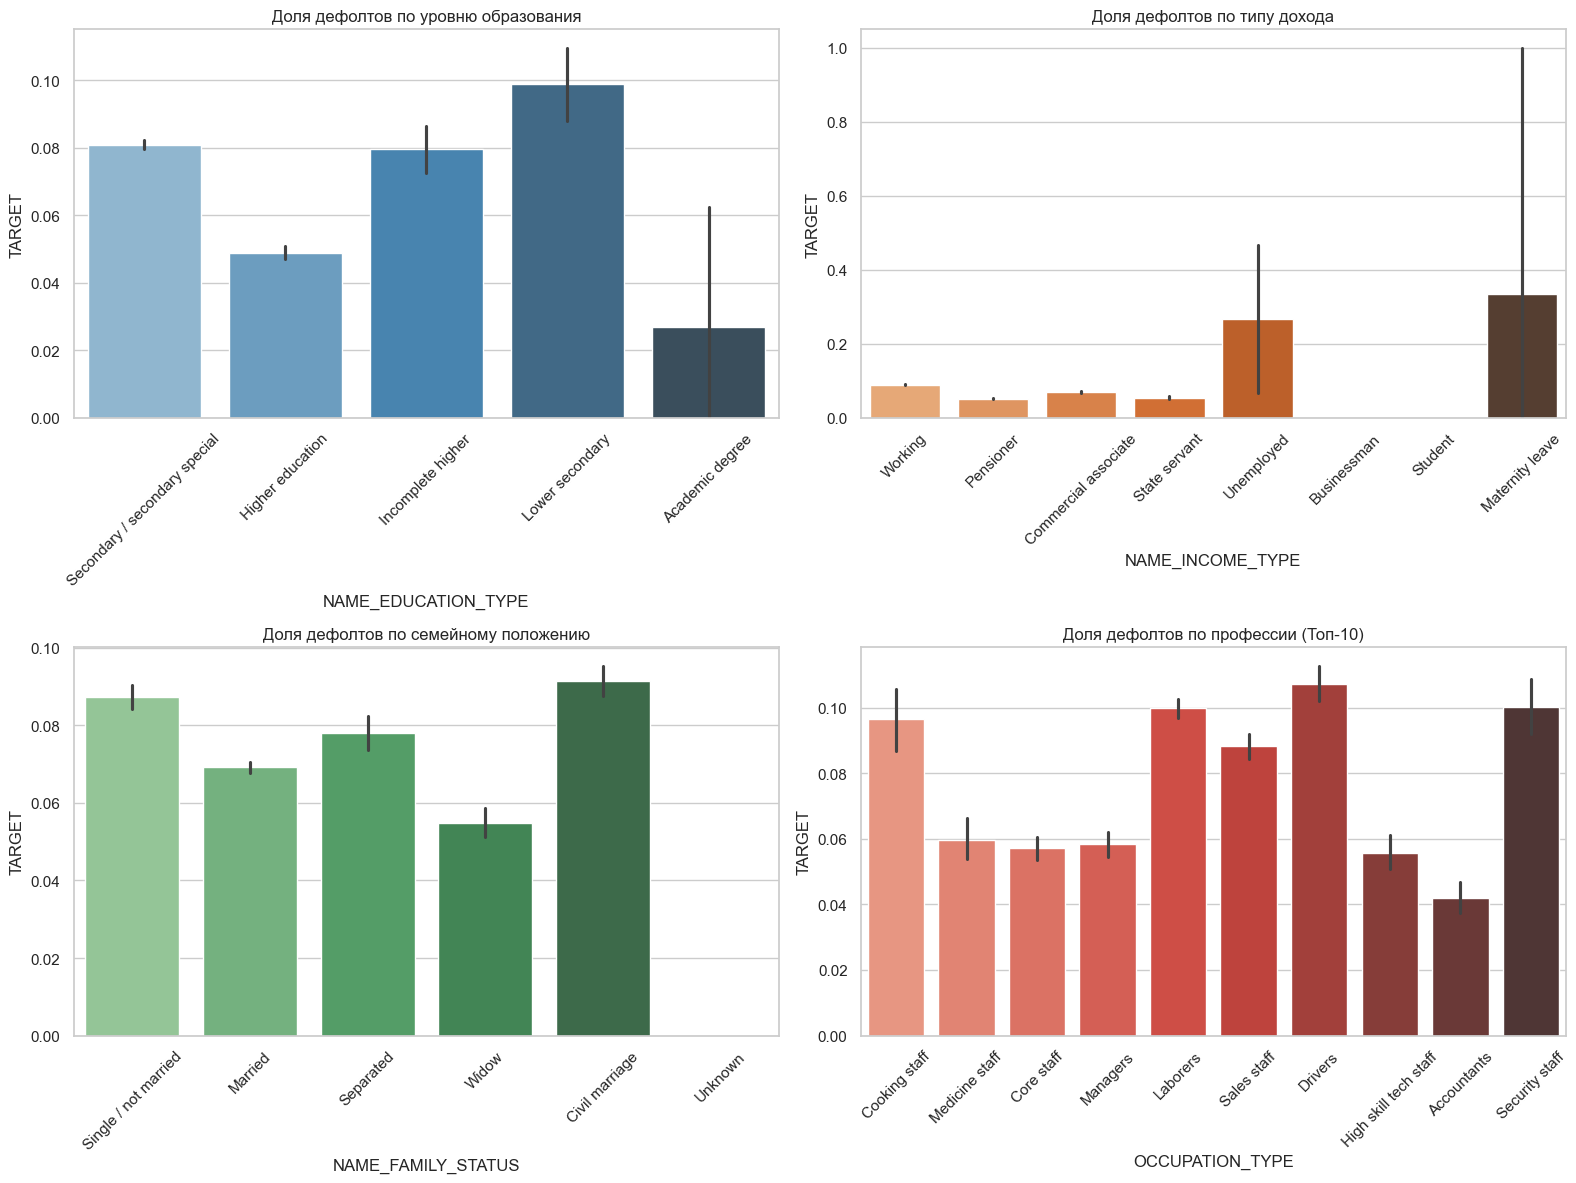

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Образование
sns.barplot(x='NAME_EDUCATION_TYPE', y='TARGET', data=train, ax=axes[0, 0], palette="Blues_d")
axes[0, 0].set_title('Доля дефолтов по уровню образования')
axes[0, 0].tick_params(axis='x', rotation=45)

# Тип дохода
sns.barplot(x='NAME_INCOME_TYPE', y='TARGET', data=train, ax=axes[0, 1], palette="Oranges_d")
axes[0, 1].set_title('Доля дефолтов по типу дохода')
axes[0, 1].tick_params(axis='x', rotation=45)

# Семейное положение
sns.barplot(x='NAME_FAMILY_STATUS', y='TARGET', data=train, ax=axes[1, 0], palette="Greens_d")
axes[1, 0].set_title('Доля дефолтов по семейному положению')
axes[1, 0].tick_params(axis='x', rotation=45)

# Тип занятости (топ-10 самых частых)
top_occ = train['OCCUPATION_TYPE'].value_counts().nlargest(10).index
sns.barplot(x='OCCUPATION_TYPE', y='TARGET', data=train[train['OCCUPATION_TYPE'].isin(top_occ)], ax=axes[1, 1], palette="Reds_d")
axes[1, 1].set_title('Доля дефолтов по профессии (Топ-10)')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

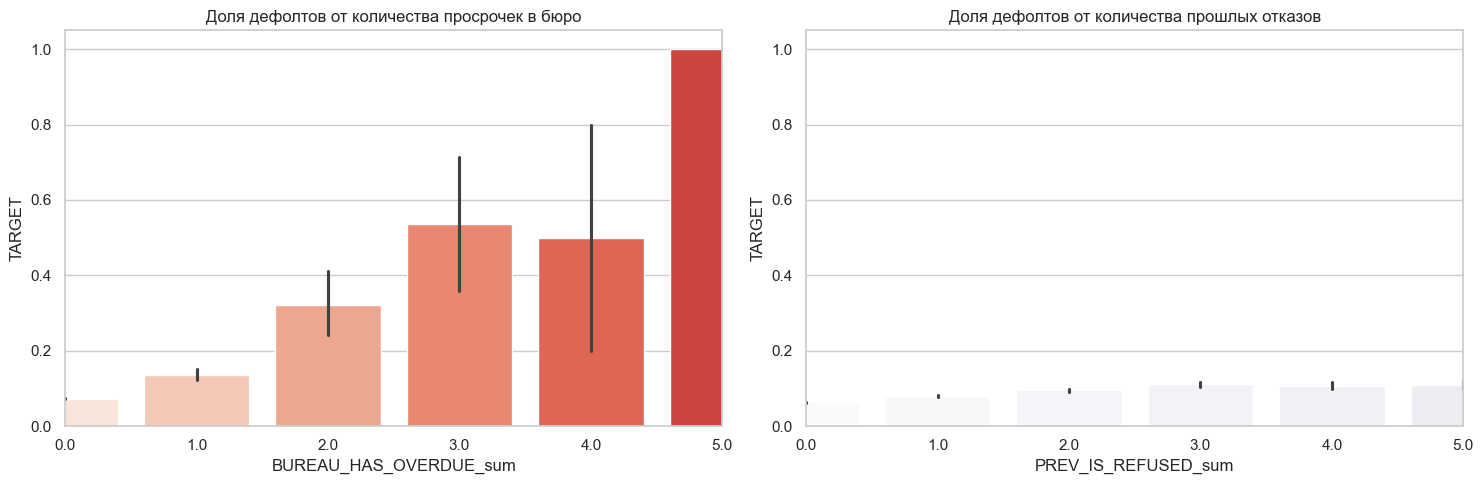

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Количество просрочек в других банках
sns.barplot(x='BUREAU_HAS_OVERDUE_sum', y='TARGET', data=train, ax=axes[0], palette="Reds")
axes[0].set_title('Доля дефолтов от количества просрочек в бюро')
axes[0].set_xlim(0, 5) # Ограничим ось X для красоты (там могут быть выбросы)

# Количество отказов в этом банке
sns.barplot(x='PREV_IS_REFUSED_sum', y='TARGET', data=train, ax=axes[1], palette="Purples")
axes[1].set_title('Доля дефолтов от количества прошлых отказов')
axes[1].set_xlim(0, 5)

plt.tight_layout()
plt.show()

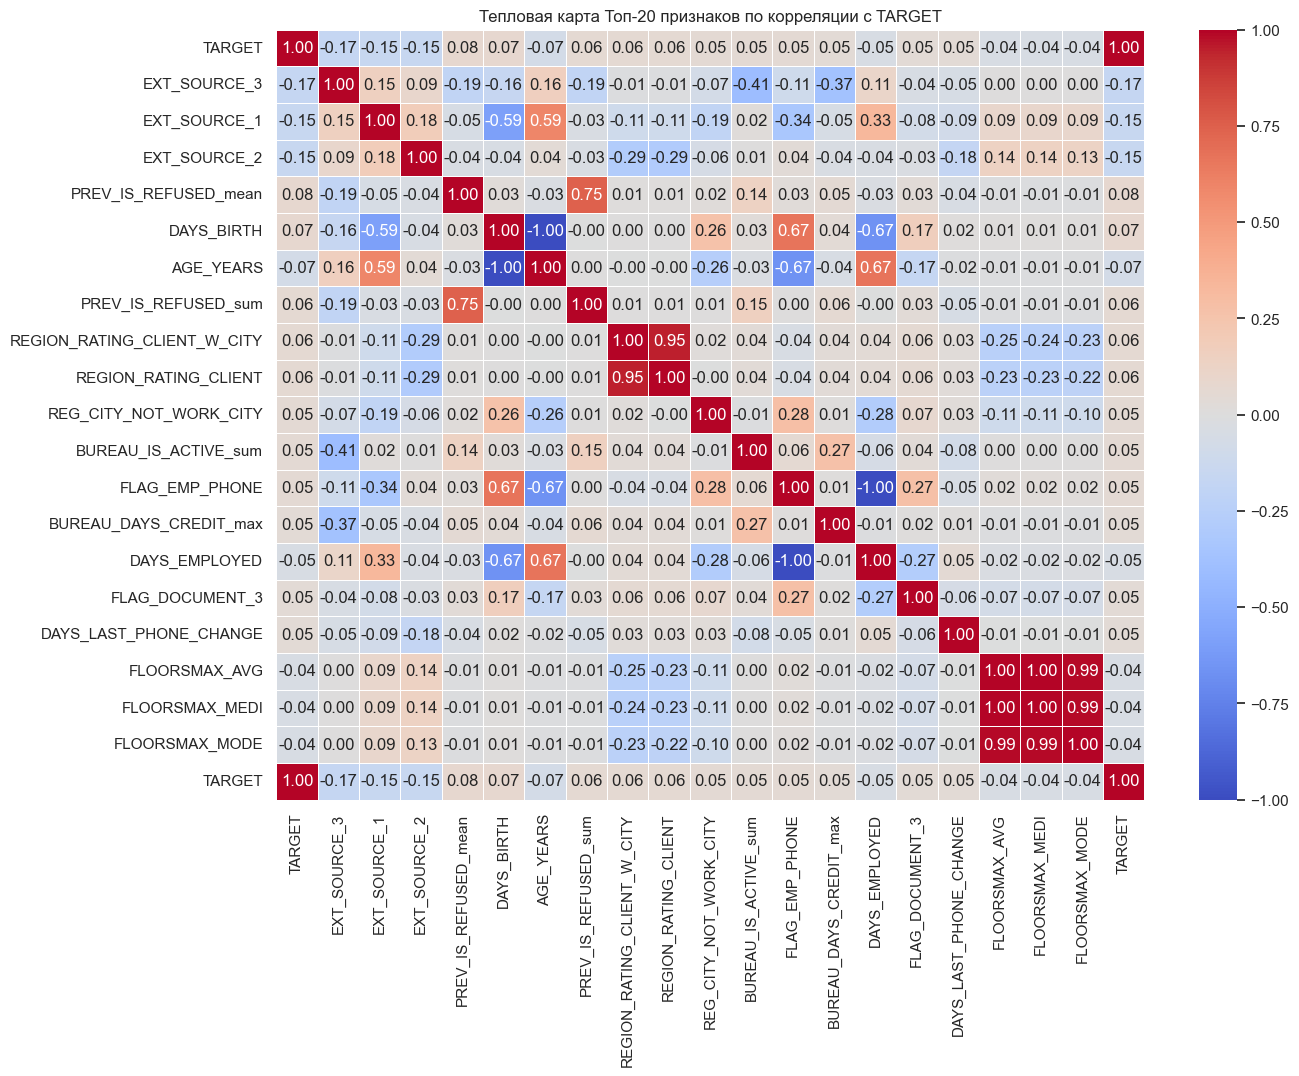

In [8]:
# Берем только числовые колонки
num_df = train.select_dtypes(include=[np.number])

# Считаем корреляцию с TARGET (по модулю, так как нам важна и прямая, и обратная связь)
corr_with_target = num_df.corrwith(train['TARGET']).abs().sort_values(ascending=False)

# Берем топ-20
top_20_cols = corr_with_target.head(20).index.tolist() + ['TARGET']

plt.figure(figsize=(14, 10))
sns.heatmap(train[top_20_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Тепловая карта Топ-20 признаков по корреляции с TARGET')
plt.show()

In [1]:
import pandas as pd
from pathlib import Path

# Пути
ROOT_DIR = Path("..").resolve() 
PROCESSED_DIR = ROOT_DIR / "data" / "processed"

# Загружаем наши текущие данные (те, что были разбиты по времени)
train = pd.read_csv(PROCESSED_DIR / "train_processed.csv")
val = pd.read_csv(PROCESSED_DIR / "val_processed.csv")
test = pd.read_csv(PROCESSED_DIR / "test_processed.csv")

print(f"До очистки: {train.shape[1]} признаков")

# 1. Список колонок, которые мы выявили как дубликаты или ненужные
# (используем errors='ignore', чтобы код не упал, если колонки вдруг нет)
cols_to_drop = [
    'AGE_YEARS',                      # Дубликат DAYS_BIRTH
    'EMPLOYED_YEARS',                 # Дубликат DAYS_EMPLOYED
    'FLOORSMAX_MEDI',                 # Дубликат FLOORSMAX_AVG
    'FLOORSMAX_MODE',                 # Дубликат FLOORSMAX_AVG
    'REGION_RATING_CLIENT_W_CITY',    # Дубликат REGION_RATING_CLIENT (корр. 0.95)
    
    # Дополнительно: убираем технические/мусорные колонки, которые не несут смысла
    'FLAG_MOBIL',                     # У всех 1, нулевая дисперсия
    'FLAG_CONT_MOBILE',               # Почти у всех 1
]

# Удаляем эти колонки из всех трех выборок
train_clean = train.drop(columns=cols_to_drop, errors='ignore')
val_clean = val.drop(columns=cols_to_drop, errors='ignore')
test_clean = test.drop(columns=cols_to_drop, errors='ignore')

print(f"После очистки: {train_clean.shape[1]} признаков")

# Проверяем, что не осталось бесконечных значений (inf), которые ломают модели
# Заменяем inf на NaN, чтобы CatBoost сам с ними справился
import numpy as np
for df in [train_clean, val_clean, test_clean]:
    df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Сохраняем очищенные данные (добавим суффикс _clean)
train_clean.to_csv(PROCESSED_DIR / "train_clean.csv", index=False)
val_clean.to_csv(PROCESSED_DIR / "val_clean.csv", index=False)
test_clean.to_csv(PROCESSED_DIR / "test_clean.csv", index=False)

print("Очищенные датасеты сохранены (train_clean.csv, val_clean.csv, test_clean.csv).")

До очистки: 145 признаков
После очистки: 140 признаков
Очищенные датасеты сохранены (train_clean.csv, val_clean.csv, test_clean.csv).
